# SmartPark AI Week 4 Data Quality

Open this notebook in Google Colab and select **Runtime → Run all**. It needs a CPU runtime and internet access for setup. The results appear below each section and the generated files are collected in a downloadable ZIP. No credentials or model API keys are required.

Topic 3 used the **Computer Vision / Images** pathway. The hand-off is six prepared synthetic shape images and their manifests. The lab's cleaned JSONL and pickle filenames are used for equivalent image-quality records. A record refers to a repository-relative image path and carries labels and provenance. The pickle is a list of the same plain dictionaries for Python notebook use. Only load pickles you trust.

This review uses the Part B images as candidates and the Part C outputs as corroborating evidence. The images were supplied for classroom practice. Approval to redistribute the teaching material and suitability for SmartPark model development are both pending.

Sources for the audit are the [Week 2 requirements](https://github.com/lejun10290000/AI-Engineering--SmartPark-AI/blob/main/docs/week2_requirements.md), [evaluation criteria](https://github.com/lejun10290000/AI-Engineering--SmartPark-AI/blob/main/docs/week2_evaluation_criteria.md), [Week 3 inventory](https://github.com/lejun10290000/AI-Engineering--SmartPark-AI/blob/main/docs/week3_data_inventory.md) and [pipeline diagram](https://github.com/lejun10290000/AI-Engineering--SmartPark-AI/blob/main/docs/week3_pipeline_diagram.png).

## Part A0 Quality gate plan

| Topic 2 requirement | Required data | Quality dimensions and observable checks | Decision |
|---|---|---|---|
| FR1 Parking-bay occupancy detection | Miniature overhead frames, bay IDs and labelled occupied/vacant states | Completeness and accuracy. Check image presence and readability, compare files to recorded fingerprints, then verify bay labels against held-out frames. | Hold prototype use if scene and occupancy annotations are missing. |
| RAI1 Safe parking guidance | Reliable occupied/vacant labels and examples of uncertain or unavailable bays | Accuracy, timeliness and consistency. Check source versions, verify annotation and layout alignment, and test no recommendation when a bay is occupied or uncertain. | Hold guidance evaluation if annotations or the applicable source version cannot be verified. |

Use exact image fingerprints to check uniqueness. For the practice hand-off, hold a candidate if its bytes, decoding, labels, lineage or required PNG format disagree with the Topic 3 contract. Same-byte Part B/C counterparts can confirm repository consistency across paths, but cannot replace approved source checksums.

In [1]:
import importlib.util
import subprocess
import sys

dependencies = {"pandera": "pandera[pandas]==0.26.1", "pandas": "pandas>=2.1.1",
                "PIL": "Pillow", "matplotlib": "matplotlib"}
missing = [package for module, package in dependencies.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

## Part A1 Verify the image hand-off

The Colab setup checks out the exact Week 3 revision used in the review. The manifests must describe the same one-to-one source set. The notebook stops if their indexes disagree. Recorded-vs-observed file properties are tested separately so their failures can be triaged.

In [2]:
from collections import defaultdict
from hashlib import sha256
from pathlib import Path
from tempfile import mkdtemp
import json
import os
import pickle
import re
import shutil

import matplotlib.pyplot as plt
import pandas as pd
import pandera
import pandera.pandas as pa
from IPython.display import display
from PIL import Image

REPOSITORY = "https://github.com/lejun10290000/AI-Engineering--SmartPark-AI.git"
WEEK3_REVISION = "a674686f55874905d7b24f4c9f4eee189a62a816"
COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False

if "SMARTPARK_SOURCE_DIR" in os.environ:
    SOURCE = Path(os.environ["SMARTPARK_SOURCE_DIR"]).resolve()
else:
    SOURCE = Path(mkdtemp(prefix="smartpark-week3-"))
    subprocess.run(["git", "init", "-q", str(SOURCE)], check=True)
    subprocess.run(["git", "-C", str(SOURCE), "fetch", "-q", "--depth=1",
                    REPOSITORY, WEEK3_REVISION], check=True)
    subprocess.run(["git", "-C", str(SOURCE), "checkout", "-q", "--detach", "FETCH_HEAD"], check=True)

default_output = Path("/content/smartpark_week4") if COLAB else Path.cwd() / "smartpark_week4"
OUTPUT = Path(os.environ.get("SMARTPARK_OUTPUT_DIR", default_output)).resolve()
if OUTPUT == SOURCE or SOURCE in OUTPUT.parents:
    raise ValueError("Choose an output directory outside the Week 3 checkout.")

part_b = pd.read_csv(SOURCE / "data/processed/image_manifest.csv", dtype=str, keep_default_na=False)
lineage = json.loads((SOURCE / "data/week3_manifest.json").read_text(encoding="utf-8"))
part_c_dir = SOURCE / "data/pipeline_v1/images"
part_c = json.loads((part_c_dir / "pipeline_manifest.json").read_text(encoding="utf-8"))

def index_unique(entries, key):
    index = {entry[key]: entry for entry in entries}
    if len(index) != len(entries) or "" in index:
        raise ValueError(f"Missing or duplicate identity in {key}")
    return index

labels = index_unique(part_b.to_dict("records"), "filename")
lineage_by_name = index_unique([
    {**entry, "filename": Path(entry["source_filename"]).name}
    for entry in lineage["records"]
], "filename")
c_map = index_unique(part_c["source_output_mapping"], "source")
c_sources = index_unique([
    {**entry, "filename": Path(entry["path"]).name} for entry in part_c["sources"]
], "filename")
c_outputs = part_c["outputs"]
c_sizes = part_c["validation"]["output_bytes"]
if (not labels or not (set(labels) == set(lineage_by_name) == set(c_map) == set(c_sources))
        or len(c_outputs) != len(c_sizes) or len(set(c_outputs)) != len(labels)
        or sorted(entry["output"] for entry in c_map.values()) != sorted(c_outputs)
        or part_c["validation"]["output_count"] != len(c_outputs)
        or part_c["inspection"]["image_count"] != len(labels)):
    raise ValueError("Week 3 hand-off indexes disagree. Verify the three input manifests.")

c_expected_sizes = dict(zip(c_outputs, c_sizes))
expected_dimensions = tuple(part_c["configuration"]["resize"])
expected_mode = "RGB"
print(f"Week 3 revision {WEEK3_REVISION}")
print(f"Hand-off index matched {len(labels)} image labels, lineage entries and Part C mappings.")
print(f"Prepared contract is PNG / {expected_mode} / {expected_dimensions[0]} x {expected_dimensions[1]}.")
print(f"pandas {pd.__version__} | pandera {pandera.__version__}")

Week 3 revision a674686f55874905d7b24f4c9f4eee189a62a816
Hand-off index matched 6 image labels, lineage entries and Part C mappings.
Prepared contract is PNG / RGB / 224 x 224.
pandas 3.1.1 | pandera 0.26.1


## Parts A2 and A3 Profile and inspect the images

The inventory checks byte identity, PNG integrity and full decode separately. Mode comes from the PNG header, so even an unreadable image can report a header mode. The RGB pixel fingerprint is computed only after successful verification and decoding. Failures stay visible in the inspection table.

In [3]:
def inspect_image(path):
    result = {"exists": path.is_file(), "size_bytes": None, "file_hash": "",
              "pixel_hash": "", "format": "", "mode": "", "dimensions": (),
              "readable": False, "error": ""}
    if not result["exists"]:
        result["error"] = "File missing"
        return result
    payload = path.read_bytes()
    result.update(size_bytes=len(payload), file_hash=sha256(payload).hexdigest())
    try:
        with Image.open(path) as image:
            result.update(format=image.format, mode=image.mode, dimensions=image.size)
            image.verify()
        with Image.open(path) as image:
            image.load()
            rgb = image.convert("RGB")
            pixels_with_size = f"{rgb.width}x{rgb.height}\n".encode() + rgb.tobytes()
            result.update(readable=True, pixel_hash=sha256(pixels_with_size).hexdigest())
    except (OSError, SyntaxError, ValueError) as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"
    return result

inventory = []
for name, label in sorted(labels.items()):
    trace, cv_source = lineage_by_name[name], c_sources[name]
    b_path, c_name = label["output"], c_map[name]["output"]
    b_image, c_image = inspect_image(SOURCE / b_path), inspect_image(part_c_dir / c_name)
    reference_hash = trace["prepared_sha256"]
    source_hash = label["source_sha256"]
    lineage_ok = (
        bool(label["source"] and b_path)
        and bool(re.fullmatch(r"[0-9a-f]{64}", source_hash))
        and bool(re.fullmatch(r"[0-9a-f]{64}", reference_hash))
        and label["source"] == trace["source_filename"] == cv_source["path"]
        and source_hash == trace["source_sha256"] == cv_source["sha256"]
        and b_path == trace["prepared_output"]
    )
    format_ok = all(
        im["format"] == "PNG" and im["mode"] == expected_mode
        and im["dimensions"] == expected_dimensions
        for im in (b_image, c_image)
    ) and (label["output_mode"], label["output_width"], label["output_height"]) == (
        expected_mode, *map(str, expected_dimensions)
    )
    inventory.append({
        "filename": name, "source": label["source"], "source_sha256": source_hash,
        "shape": label["shape_label"], "colour": label["colour"], "b_path": b_path,
        "c_path": f"data/pipeline_v1/images/{c_name}",
        "source_version": trace["source_version"], "rights": trace["access_rights"],
        "expected_sha256": reference_hash, "actual_sha256": b_image["file_hash"],
        "c_sha256": c_image["file_hash"], "pixel_sha256": b_image["pixel_hash"],
        "b_mode": b_image["mode"], "c_mode": c_image["mode"],
        "b_dimensions": str(b_image["dimensions"]), "c_dimensions": str(c_image["dimensions"]),
        "b_error": b_image["error"], "c_error": c_image["error"],
        "c_size_expected": c_expected_sizes[c_name], "c_size_actual": c_image["size_bytes"],
        "files_present": b_image["exists"] and c_image["exists"],
        "labels_valid": label["shape_label"] in {"circle", "square"}
                        and label["colour"] in {"red", "blue"},
        "lineage_consistent": lineage_ok,
        "images_readable": b_image["readable"] and c_image["readable"],
        "format_consistent": format_ok,
        "part_b_hash_matches": bool(b_image["file_hash"]) and b_image["file_hash"] == reference_hash,
        "part_c_size_matches": c_image["size_bytes"] == c_expected_sizes[c_name],
        "cross_stage_same_bytes": bool(b_image["file_hash"]) and b_image["file_hash"] == c_image["file_hash"],
        "source_version_known": bool(trace["source_version"].strip())
                                and trace["source_version"].casefold() != "not verified",
        "rights_recorded_as_verified": trace["access_rights"].strip().casefold() == "verified",
    })

profile = pd.DataFrame(inventory).set_index("filename", drop=False)
display(profile[["shape", "colour", "b_mode", "b_dimensions", "b_error",
                 "part_b_hash_matches", "c_size_expected", "c_size_actual",
                 "cross_stage_same_bytes"]].reset_index(drop=True))

,shape,colour,b_mode,b_dimensions,b_error,part_b_hash_matches,c_size_expected,c_size_actual,cross_stage_same_bytes
0,circle,red,P,"(224, 224)",,False,5490,1895,True
1,square,blue,P,"(224, 224)",SyntaxError: broken PNG file (bad header check...,False,1190,424,True
2,circle,blue,P,"(224, 224)",,False,4433,1546,True
3,square,red,P,"(224, 224)",,False,1049,376,True
4,circle,red,P,"(224, 224)",,False,3504,1279,True
5,square,blue,P,"(224, 224)",,False,954,319,True


In [4]:
# Visually inspect all decodable images in the running session.
samples = profile[profile["images_readable"]]
if not samples.empty:
    fig, axes = plt.subplots(1, len(samples), figsize=(2.3 * len(samples), 2.8), squeeze=False)
    for axis, row in zip(axes.ravel(), samples.itertuples()):
        with Image.open(SOURCE / row.b_path) as im:
            axis.imshow(im.convert("RGB"))
        axis.set_title(f"{row.filename}\n{row.colour} {row.shape}")
        axis.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

Contact sheet generated at runtime.


### Manual inspection notes

- **shape_01.png** appears to show a red circle with white padding, agreeing with the label. The PNG is palette mode P and its fingerprint differs from the recorded fingerprint. Keep it on hold pending a trusted export.
- **shape_03.png** appears to show a blue circle and **shape_04.png** a red square, matching their labels. Shape size varies visibly across the contact sheet. Appearance supports the teaching label, but does not establish the preprocessing history or the quality of a future parking-bay label.
- **shape_02.png** reports a broken PNG checksum. Its Part B and Part C copies are identical. Hold it and regenerate it from the authorised original. A visual label check was unavailable.

A simple dimension rule would miss whether the visual shape matches its label, whether the padding obscures relevant details, and whether the content depicts the parking problem at all. These affect accuracy and coverage.

## Parts A4 and A5 Run Pandera validation and triage

Each rule is evaluated once per source record with Pandera's lazy validation. The output includes evidence, classification and action. Physical integrity or data-contract failures quarantine a record. Unverified source dates and sharing rights are governance review flags tracked separately from file defects.

In [5]:
rules = {
    "files_present": ("Missing", "Hard fail", "Both prepared files exist", "Restore the missing authorised export"),
    "labels_valid": ("Missing or inconsistent", "Hard fail", "Shape and colour are in the Week 3 vocabulary", "Verify or correct the original annotation"),
    "lineage_consistent": ("Inconsistent", "Hard fail", "Paths and source hashes agree across the manifests", "Reconcile the source mapping"),
    "images_readable": ("Corrupted", "Hard fail", "Both PNGs pass integrity and full decoding", "Re-export from the authorised source"),
    "format_consistent": ("Inconsistent", "Hard fail", "Both headers are PNG/RGB and match the declared 224 x 224 contract", "Re-export and verify the RGB contract"),
    "part_b_hash_matches": ("Inconsistent", "Hard fail", "Part B SHA-256 equals the Week 3 lineage manifest value", "Recover trusted bytes or record a verified replacement version"),
    "part_c_size_matches": ("Inconsistent", "Hard fail", "Part C byte size equals the Week 3 pipeline manifest value", "Regenerate the Part C output and verify its manifest"),
    "source_version_known": ("Uncertain", "Review", "A source version or date appears in the lineage record", "Confirm the course archive version with the lecturer"),
    "rights_recorded_as_verified": ("Uncertain", "Review", "The lineage manifest explicitly records access rights as Verified", "Confirm permitted uses and publication rights with the lecturer"),
}

schema = pa.DataFrameSchema({
    name: pa.Column(bool, checks=pa.Check(lambda column: column, error=name), nullable=False)
    for name in rules
})
try:
    schema.validate(profile[list(rules)], lazy=True)
    raw_failures = pd.DataFrame(columns=["column", "index"])
except pa.errors.SchemaErrors as exc:
    raw_failures = exc.failure_cases
    if raw_failures["index"].isna().any():
        raise RuntimeError("A validation rule failed structurally.") from exc

def failure_evidence(rule, row):
    evidence = {
        "files_present": f"Part B: {row.b_error or 'present'} / Part C: {row.c_error or 'present'}",
        "labels_valid": f"shape={row['shape']!r}, colour={row.colour!r}",
        "lineage_consistent": f"Manifest path or hash disagreement for {row.source}",
        "images_readable": f"Part B: {row.b_error or 'OK'} / Part C: {row.c_error or 'OK'}",
        "format_consistent": f"Part B mode {row.b_mode} {row.b_dimensions} / Part C mode {row.c_mode} {row.c_dimensions}",
        "part_b_hash_matches": f"Expected {row.expected_sha256} / actual {row.actual_sha256}",
        "part_c_size_matches": f"Expected {row.c_size_expected} bytes / actual {row.c_size_actual} bytes",
        "source_version_known": row.source_version,
        "rights_recorded_as_verified": row.rights,
    }
    return evidence[rule]

failures = []
for item in raw_failures.itertuples(index=False):
    classification, severity, condition, action = rules[item.column]
    failures.append({
        "filename": item.index, "rule": item.column, "classification": classification,
        "severity": severity, "condition": condition,
        "evidence": failure_evidence(item.column, profile.loc[item.index]),
        "decision": "Quarantine" if severity == "Hard fail" else "Review",
        "follow_up": action,
    })
failure_columns = ["filename", "rule", "classification", "severity", "condition",
                   "evidence", "decision", "follow_up"]
failures = pd.DataFrame(failures, columns=failure_columns).sort_values(["filename", "rule"])
failure_counts = failures["rule"].value_counts()
summary = pd.DataFrame([
    {"rule": name, "condition": condition, "severity": severity,
     "failures": int(failure_counts.get(name, 0)),
     "failed_pct": round(100 * failure_counts.get(name, 0) / len(profile), 1)}
    for name, (_, severity, condition, _) in rules.items()
])
quarantined = set(failures.loc[failures["decision"] == "Quarantine", "filename"])
display(summary)
print(f"{len(failures)} flagged conditions across {len(profile)} records. "
      f"{len(quarantined)} records quarantined.")

,rule,condition,severity,failures,failed_pct
0,files_present,Both prepared files exist,Hard fail,0,0.0
1,labels_valid,Shape and colour are in the Week 3 vocabulary,Hard fail,0,0.0
2,lineage_consistent,Paths and source hashes agree across the manif...,Hard fail,0,0.0
3,images_readable,Both PNGs pass integrity and full decoding,Hard fail,1,16.7
4,format_consistent,Both headers are PNG/RGB and match the declare...,Hard fail,6,100.0
5,part_b_hash_matches,Part B SHA-256 equals the Week 3 lineage manif...,Hard fail,6,100.0
6,part_c_size_matches,Part C byte size equals the Week 3 pipeline ma...,Hard fail,6,100.0
7,source_version_known,A source version or date appears in the lineag...,Review,6,100.0
8,rights_recorded_as_verified,The lineage manifest explicitly records access...,Review,6,100.0


31 flagged conditions across 6 records. 6 records quarantined.


| Item | Evidence and interpretation | Triage |
|---|---|---|
| shape_01.png | Readable with a plausible label. The Part B and C bytes agree with each other but disagree with the recorded Part B SHA-256 and Part C size. The cause is unresolved. | Quarantine and compare with a trusted Week 3 export. |
| shape_02.png | Both copies fail PNG verification at IDAT. The byte-level failure is a confirmed defect. | Quarantine and regenerate both outputs. |
| shape_04.png | Readable palette-mode PNG despite the RGB contract. This may be a storage conversion. Its lineage is unresolved and its colour/shape appear plausible. | Quarantine pending verification of the conversion or a verified RGB re-export. |
| shape_06.png | Shape appears to have substantial white margin. Aspect-ratio-preserving padding is documented and can be a valid transformation. The fingerprint issue still blocks inclusion. | Preserve the observation. Review padding together with annotation geometry for future parking images. |

## Part B1 Review exact duplicates and preserve provenance

Group canonical Part B records by byte SHA-256 and by decoded RGB pixel SHA-256. The second check can detect identical rendered images with different PNG encodings. Topic 3's Part B and C copies are two outputs for one source and are not counted twice in the corpus. Conflicting labels on identical images would quarantine that group. When eligible duplicates agree, retain one reference and keep every contributing source in its lineage.

In [6]:
groups = defaultdict(list)
for row in inventory:
    if row["pixel_sha256"]:
        identity = ("rgb_pixels", row["pixel_sha256"])
    elif row["actual_sha256"]:
        identity = ("file_bytes_unreadable", row["actual_sha256"])
    else:
        identity = ("unavailable", row["filename"])
    groups[identity].append(row)

duplicate_events = []
clean_records = []
for (method, fingerprint), members in groups.items():
    candidates = [row for row in members if row["filename"] not in quarantined]
    conflict = len({(row["shape"], row["colour"]) for row in members}) > 1
    selected = candidates[0] if candidates and not conflict else None
    if len(members) > 1:
        for row in members:
            duplicate_events.append({
                "review_type": method, "fingerprint": fingerprint, "filename": row["filename"],
                "source_path": row["b_path"], "canonical": selected["filename"] if selected else "",
                "same_file_bytes": len({item["actual_sha256"] for item in members}) == 1,
                "decision": ("Hold conflicting labels" if conflict else "Hold group" if selected is None
                             else "Keep canonical" if row is selected else "Preserve provenance"),
            })
    for row in members:
        if row["cross_stage_same_bytes"]:
            duplicate_events.append({
                "review_type": "Part B/C counterparts", "fingerprint": row["actual_sha256"],
                "filename": row["filename"], "source_path": row["c_path"],
                "canonical": row["b_path"], "same_file_bytes": True,
                "decision": "Record both paths for one source; exclude Part C copy from counts",
            })
    if selected:
        clean_records.append({
            "image_path": selected["b_path"], "sha256": selected["actual_sha256"],
            "shape_label": selected["shape"], "colour": selected["colour"],
            "source_revision": WEEK3_REVISION, "source_version": selected["source_version"],
            "rights_status": selected["rights"],
            "provenance": [{key: row[key] for key in ("source", "source_sha256", "b_path", "c_path")}
                           for row in members],
        })

duplicates = pd.DataFrame(duplicate_events, columns=[
    "review_type", "fingerprint", "filename", "source_path", "canonical",
    "same_file_bytes", "decision",
])
same_image_groups = sum(len(members) > 1 for members in groups.values())
distinct_files = len({row["actual_sha256"] for row in inventory if row["actual_sha256"]})
distinct_pixels = len({row["pixel_sha256"] for row in inventory if row["pixel_sha256"]})
print(f"Canonical input: {len(inventory)}. Distinct file hashes: {distinct_files}. "
      f"Distinct decoded RGB hashes: {distinct_pixels}.")
print(f"Exact duplicate groups across source records: {same_image_groups}. "
      f"Eligible unique records: {len(clean_records)}.")
display(duplicates)

Canonical input: 6. Distinct file hashes: 6. Distinct decoded RGB hashes: 5.
Exact duplicate groups across source records: 0. Eligible unique records: 0.


,review_type,fingerprint,filename,source_path,canonical,same_file_bytes,decision
0,Part B/C counterparts,31298799da3e3a4fb4035d5e414c2b4ad9e51f9583aea8...,shape_01.png,data/pipeline_v1/images/prepared_001.png,data/processed/images/shape_01_17a1e2828014.png,True,Record both paths for one source; exclude Part...
1,Part B/C counterparts,c9fdf6049b6e1f58411f113058769e8a99d541adaf8363...,shape_02.png,data/pipeline_v1/images/prepared_002.png,data/processed/images/shape_02_dfa0925ff27b.png,True,Record both paths for one source; exclude Part...
2,Part B/C counterparts,8745802444798ef5be3ef931bd9ec4eb6e3a59e6758a74...,shape_03.png,data/pipeline_v1/images/prepared_003.png,data/processed/images/shape_03_bb10030d1f0b.png,True,Record both paths for one source; exclude Part...
3,Part B/C counterparts,1868af6dafbe2a80493f507201b081ebd9f385a2e40396...,shape_04.png,data/pipeline_v1/images/prepared_004.png,data/processed/images/shape_04_2514fccc54d1.png,True,Record both paths for one source; exclude Part...
4,Part B/C counterparts,bf58a1d80c4d16f48b2d87af7c3cda40c0d49a24489808...,shape_05.png,data/pipeline_v1/images/prepared_005.png,data/processed/images/shape_05_94d4f1150747.png,True,Record both paths for one source; exclude Part...
5,Part B/C counterparts,27fb6dfffb28ca8d8f93ba6fe37568865fcb9bbc72b18b...,shape_06.png,data/pipeline_v1/images/prepared_006.png,data/processed/images/shape_06_5908f2d0dabc.png,True,Record both paths for one source; exclude Part...


## Part B2 Coverage

The input source grouping uses the parent directory recorded in the manifest. The domain-relevant secondary grouping uses the original shape and colour labels to show practice-set composition. A project-ready dataset would cover occupied and vacant bays, uncertain states, lighting variation, occlusion and temporally ordered tracking events. These conditions require separately annotated miniature parking footage.

In [7]:
source_counts = profile["source"].map(lambda name: Path(name).parent.as_posix()).value_counts()
practice_labels = pd.crosstab(profile["shape"], profile["colour"])
display(source_counts.rename("candidate_images").to_frame())
display(practice_labels)

with plt.ioff():
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
source_counts.plot.barh(ax=axes[0], color="#00796b")
axes[0].set_yticks(range(len(source_counts)), [Path(src).name for src in source_counts.index])
axes[0].set_title("Week 3 candidates by source")
axes[0].set_xlabel("Image records")
axes[0].set_ylabel("")
practice_labels.plot.bar(ax=axes[1], color={"blue": "#3157a4", "red": "#b83b49"}, rot=0)
axes[1].set_title("Practice labels by shape and colour")
axes[1].set_ylabel("Image records")
axes[1].set_xlabel("")
axes[1].set_ylim(0, max(1, practice_labels.to_numpy().max()) * 1.25)
axes[1].legend(loc="upper center", ncol=2, frameon=False)
for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"SmartPark AI Week 4 coverage | {len(clean_records)} records passed the quality gate")
fig.tight_layout()

,candidate_images
source,
topic3_dummy_datasets/03_images,6


colour,blue,red
shape,,
circle,1,2
square,2,1


## Parts B3 and B4 Bias and governance

| Risk | Source or transformation → prepared evidence → downstream opportunity → effect | Mitigation and later test |
|---|---|---|
| Representation | Six synthetic shapes with no bays, vehicles, lighting variation or ordered clips → no occupied/vacant or track examples → a later model or index would lack evidence for those conditions → a driver could get unreliable vacancy or position guidance. | Collect varied miniature scenes and held-out clips. Evaluate occupancy and tracking across lighting, layout and occlusion scenarios. |
| Measurement | Shape/colour labels and fixed-size padding → visual properties that do not encode bay occupancy and may distort size cues → any later vision or retrieval stage could rely on colour or canvas features → results could fail when vehicle colours, sizes or viewpoints change. | Label bay states and vehicle tracks independently, record geometry and transform annotations with the image. Check small/partially obscured vehicles and false-vacant results. |
| Historical | The underlying scope and dates of future parking footage are unknown. The classroom set has no site or date history to test. | Record capture dates, layouts and camera versions. Recheck earlier and current sessions after a setup change. |

SmartPark's planned downstream system uses image ingestion, occupancy detection, tracking and guidance. If the course later requires a retrieval or generation demonstration, only use an authorised evidence collection and test whether it retrieves current, relevant evidence. The Week 4 flags provide no system-level fairness result.

The course is the recorded source provider. Archive version and public redistribution rights require verification. Five decodable samples show simple shapes, and the inventory describes the pack as synthetic. The corrupt file cannot be inspected visually. Consent for the classroom shapes is not applicable on the available evidence. For future footage, keep the view on the miniature layout, avoid identifiable people and real plates, verify the collection basis before retaining any personal data, and assign access, retention, deletion and update ownership. The Week 4 exports contain references and audit evidence. The contact sheet is rendered during the run.

## Part C Export and verify the evidence

The review reconstructs both cleaned formats from eligible unique records. An empty JSONL file and a pickle containing an empty list represent zero admitted records. The validation table and report document the reason for each hold. Topic 7 may use reviewed records only after the documented gate is cleared and project-relevant data is available.

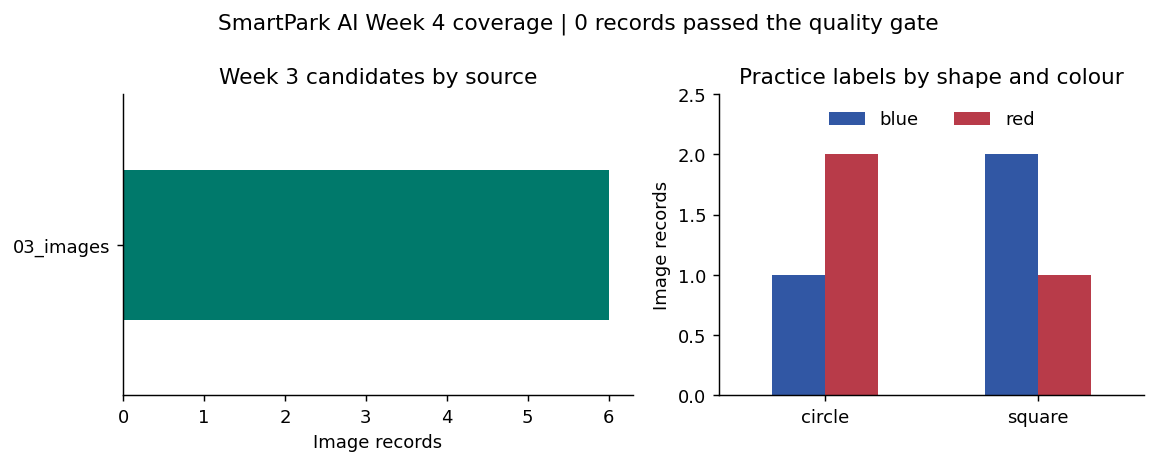

Round-trip passed: 0 JSONL records and 0 pickle records.
Project quality gate: HOLD. The input lacks labelled parking scenes and permissions are unverified.
Prepared practice data admitted by the file-level checks: 0
Generated evidence ZIP: week4_generated.zip


In [8]:
output_data = OUTPUT / "data"
output_docs = OUTPUT / "docs"
output_data.mkdir(parents=True, exist_ok=True)
output_docs.mkdir(parents=True, exist_ok=True)

failures.to_csv(output_docs / "week4_validation_failures.csv", index=False)
duplicates.to_csv(output_docs / "week4_duplicate_review.csv", index=False)
plot_path = output_docs / "week4_coverage_by_source.png"
fig.savefig(plot_path, dpi=130, bbox_inches="tight")
# Display consistently even when Matplotlib is running on a non-interactive backend.
with Image.open(plot_path) as plot_image:
    display(plot_image.copy())
plt.close(fig)

jsonl_path = output_data / "prepared_chunks_clean.jsonl"
pkl_path = output_data / "chunks_clean.pkl"
jsonl_path.write_text("".join(json.dumps(record, ensure_ascii=False) + "\n"
                             for record in clean_records), encoding="utf-8")
with pkl_path.open("wb") as stream:
    pickle.dump(clean_records, stream, protocol=4)
reloaded_jsonl = [json.loads(line) for line in jsonl_path.read_text(encoding="utf-8").splitlines()]
with pkl_path.open("rb") as stream:
    reloaded_pkl = pickle.load(stream)  # Reload only the file generated above in this session.
assert reloaded_jsonl == reloaded_pkl == clean_records
reviewed_paths = {row["b_path"] for row in inventory if row["filename"] not in quarantined}
assert all(record["image_path"] in reviewed_paths for record in clean_records)
print(f"Round-trip passed: {len(reloaded_jsonl)} JSONL records and {len(reloaded_pkl)} pickle records.")
print("Project quality gate: HOLD. The input lacks labelled parking scenes and permissions are unverified.")
print("Prepared practice data admitted by the file-level checks:", len(clean_records))

archive_path = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
print(f"Generated evidence ZIP: {Path(archive_path).name}")

In [9]:
# Start the evidence download in Colab.
if COLAB:
    from google.colab import files

    files.download(archive_path)

The [eight-section quality report](https://github.com/lejun10290000/AI-Engineering--SmartPark-AI/blob/main/docs/week4_data_quality_report.md) records the measured results, unresolved findings, owners and conditions for revisiting the gate.